In [1]:
!pip install pyDOE

  Preparing metadata (setup.py) ... done
  Created wheel for pyDOE: filename=pyDOE-0.3.8-py3-none-any.whl size=18167 sha256=65ae4f12fbe43f05cfc93485b69445154c53520d6255093abdc0daaeb6cf0e71
  Stored in directory: /root/.cache/pip/wheels/ce/b6/d7/c6b64746dba6433c593e471e0ac3acf4f36040456d1d160d17
Successfully built pyDOE


In [2]:
import tensorflow as tf
import numpy as np
from pyDOE import lhs
import matplotlib.pyplot as plt

from scipy.integrate import odeint

In [3]:
# Boundaries of the computational domain
t0, tfinal = 0.0, 5.0

### Non-invariant version

In [4]:
# Initial conditions
x0 = 1.0
y0 = 1.0

xt0 = 0.5
yt0 = 0.0

init_data = (x0, y0, xt0, yt0)

In [5]:
# Define the network
def build_model(nr_units = 60, nr_layers=4, summary=False):

  inp = b = tf.keras.layers.Input(shape=(1,))

  for i in range(nr_layers):
    b = tf.keras.layers.Dense(nr_units, activation='tanh')(b)
  outx = tf.keras.layers.Dense(1, activation='linear')(b)
  outy = tf.keras.layers.Dense(1, activation='linear')(b)

  outx = tf.keras.layers.Lambda(lambda x: x0 + x[0]*xt0 + (x[0]/tfinal)**2*x[1])([inp, outx])
  outy = tf.keras.layers.Lambda(lambda x: y0 + x[0]*yt0 + (x[0]/tfinal)**2*x[1])([inp, outy])

  model = tf.keras.models.Model(inp, [outx, outy])

  if summary:
    model.summary()

  return model

In [6]:
model = build_model(summary = True)

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 1)]          0           []                               
                                                                                                  
 dense (Dense)                  (None, 60)           120         ['input_1[0][0]']                
                                                                                                  
 dense_1 (Dense)                (None, 60)           3660        ['dense[0][0]']                  
                                                                                                  
 dense_2 (Dense)                (None, 60)           3660        ['dense_1[0][0]']                
                                                                                              

In [7]:
# Define the collocation points over the domain [t_0, t_1]
def defineCollocationPoints(t_bdry, N_pde=100):

    # Sample points where to evaluate the PDE
  ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N_pde)

  return ode_points

In [8]:
# Define the collocation points
de_points = defineCollocationPoints([t0, tfinal], 500)

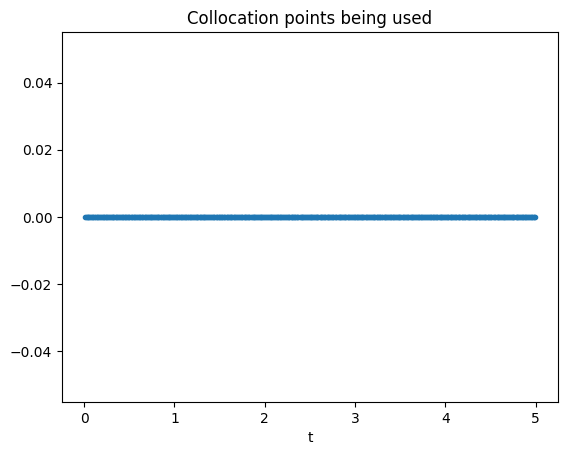

In [9]:
plt.plot(de_points[:,0], 0*de_points[:,0],'.')
plt.xlabel('t')
plt.title('Collocation points being used')
plt.savefig('CollocationPoints1D.png')

In [10]:
# The main training function
@tf.function
def train_network(odes, model):

  # DE collocation points
  t_de = odes[:,:1]

  # Outer gradient for tuning network parameters
  with tf.GradientTape() as tape:

    # Inner gradient for derivatives of u wrt x and t
    with tf.GradientTape(persistent=True) as tape2:
      tape2.watch(t_de)
      with tf.GradientTape(persistent=True) as tape3:
        tape3.watch(t_de)
        [x, y] = model(t_de)
      xt = tape3.gradient(x, t_de)
      yt = tape3.gradient(y, t_de)
    xtt = tape2.gradient(xt, t_de)
    ytt = tape2.gradient(yt, t_de)

    # Define the differential equation loss
    eqn1 = xtt + x/tf.sqrt((x**2+y**2)**3)
    eqn2 = ytt + y/tf.sqrt((x**2+y**2)**3)

    loss = tf.reduce_mean(tf.square(eqn1) + tf.square(eqn2))

  grads = tape.gradient(loss, model.trainable_variables)
  return loss, grads

In [11]:
def PINNtrain(de_points, epochs=1000):

  # Total number of collocation points
  N_de = len(de_points)

  # Batch size
  bs_de = N_de

  # Learning rate
  lr_model = 1e-3

  epoch_loss = np.zeros(epochs)
  nr_batches = 0

  # Generate the tf.Dataset for the differential equations points
  ds = tf.data.Dataset.from_tensor_slices(de_points.astype(np.float32))
  ds = ds.cache().shuffle(N_de).batch(bs_de)

  # Generate the model
  opt = tf.keras.optimizers.Adam(lr_model)
  model = build_model()

  # Main training loop
  for i in range(epochs):

    # Training for that epoch
    for des in ds:

      # Train the network
      DEloss, grads = train_network(des, model)

      # Gradient step
      opt.apply_gradients(zip(grads, model.trainable_variables))

      epoch_loss[i] += DEloss
      nr_batches += 1

    # Get total epoch loss
    epoch_loss[i] /= nr_batches
    nr_batches = 0

    if (np.mod(i, 100)==0):
      print("DE loss in {}th epoch: {: 6.4f}.".format(i, DEloss))

  return epoch_loss, model

In [12]:
epochs = 5000
loss, model = PINNtrain(de_points, epochs)

DE loss in 0th epoch:  0.0380.
DE loss in 100th epoch:  0.0117.
DE loss in 200th epoch:  0.0098.
DE loss in 300th epoch:  0.0094.
DE loss in 400th epoch:  0.0083.
DE loss in 500th epoch:  0.0101.
DE loss in 600th epoch:  0.0092.
DE loss in 700th epoch:  0.0082.
DE loss in 800th epoch:  0.0085.
DE loss in 900th epoch:  0.0078.
DE loss in 1000th epoch:  0.0098.
DE loss in 1100th epoch:  0.0077.
DE loss in 1200th epoch:  0.0083.
DE loss in 1300th epoch:  0.0077.
DE loss in 1400th epoch:  0.0190.
DE loss in 1500th epoch:  0.0099.
DE loss in 1600th epoch:  0.0107.
DE loss in 1700th epoch:  0.0125.
DE loss in 1800th epoch:  0.0091.
DE loss in 1900th epoch:  0.0113.
DE loss in 2000th epoch:  0.0156.
DE loss in 2100th epoch:  0.0099.
DE loss in 2200th epoch:  0.0086.
DE loss in 2300th epoch:  0.0084.
DE loss in 2400th epoch:  0.0080.
DE loss in 2500th epoch:  0.0094.
DE loss in 2600th epoch:  0.0077.
DE loss in 2700th epoch:  0.0101.
DE loss in 2800th epoch:  0.0076.
DE loss in 2900th epoch:  

In [13]:
# Initial angular momentum
H0 = y0 * xt0 - x0 * yt0

# Grid where to evaluate the model
m = 200
t = np.linspace(t0, tfinal, m)

# Model prediction
tt = tf.cast(tf.Variable(np.expand_dims(t, axis=1)), tf.float32)
with tf.GradientTape(persistent=True) as tape:
  tape.watch(tt)
  [x, y] = model(tt)
xt = tape.gradient(x, tt)
yt = tape.gradient(y, tt)

H = y*xt - x*yt

Text(0, 0.5, 'Conservation Error H')

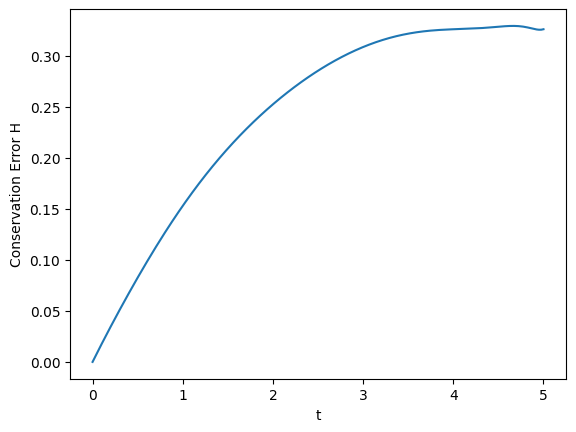

In [14]:
plt.plot(t, H-H0)
plt.xlabel('t')
plt.ylabel('Conservation Error H')

In [15]:
## RK reference solution
def kepler(w, t):
  x, y, xt, yt = w
  dwdt = [xt, yt, -x/np.sqrt((x**2+y**2)**3), -y/np.sqrt((x**2+y**2)**3)]
  return dwdt

urk = odeint(kepler, init_data, t)

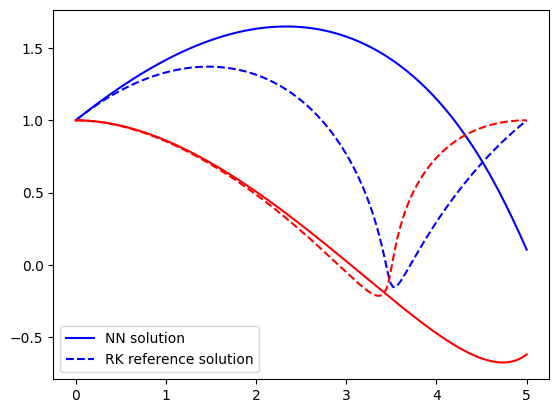

In [16]:
plt.plot(t, x[:,0],'b')
plt.plot(t, urk[:,0],'b--')

plt.plot(t, y[:,0],'r')
plt.plot(t, urk[:,1],'r--')
plt.legend(['NN solution', 'RK reference solution'])

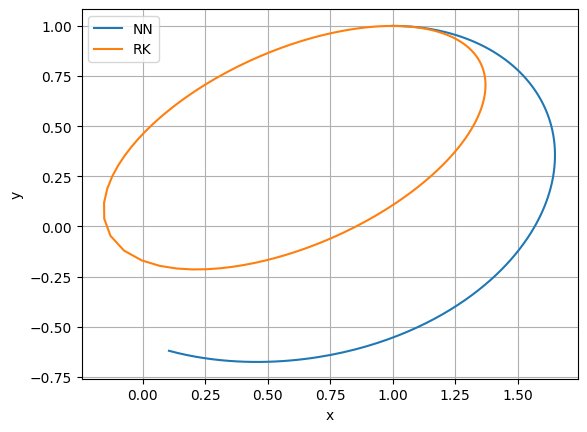

In [17]:
plt.plot(x[:,0], y[:,0])
plt.plot(urk[:,0], urk[:,1])
plt.xlabel('x')
plt.ylabel('y')
plt.grid()

plt.legend(['NN','RK'])

In [18]:
# Errors
print(f'MSE: {np.mean((x[:,0]-urk[:,0])**2)}')
print(f'MAE: {np.mean(np.abs(x[:,0]-urk[:,0]))}')

MSE: 0.40949326753616333
MAE: 0.4730045795440674


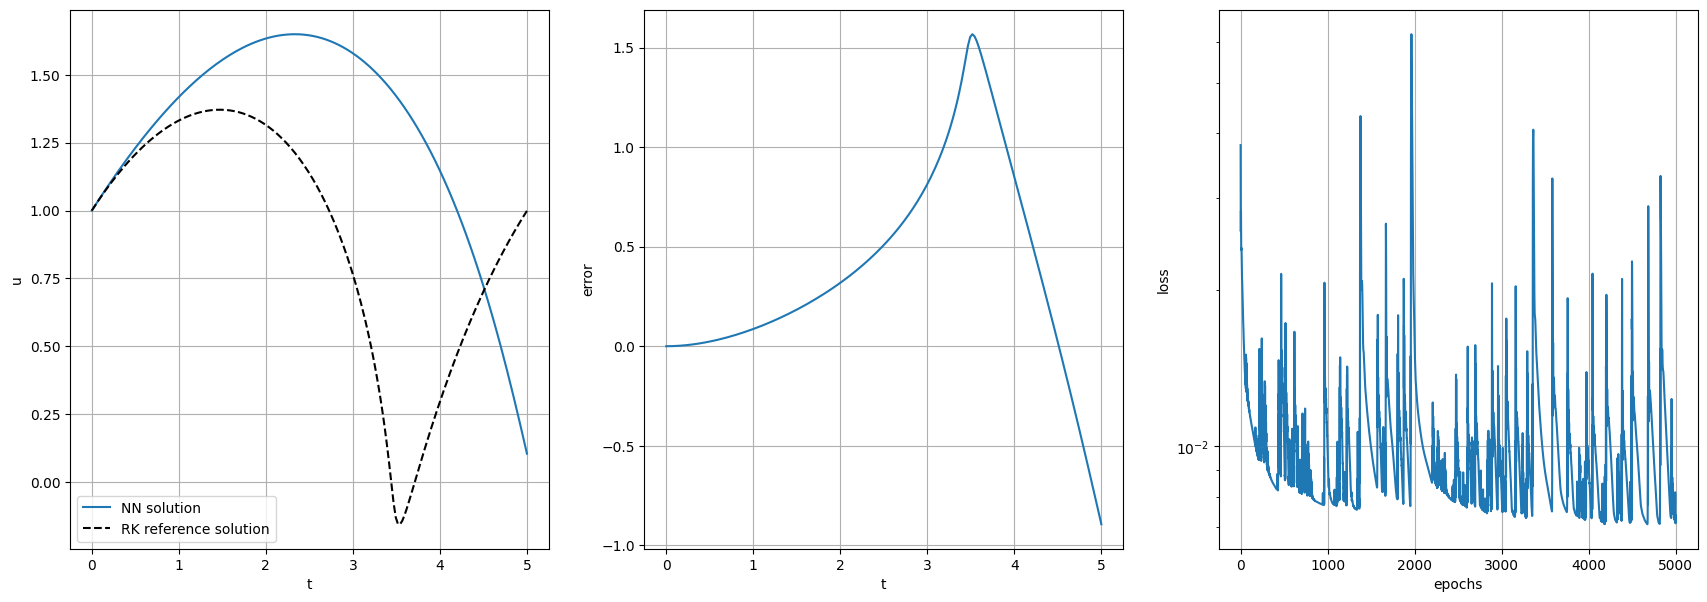

In [19]:
# Plot the solution
fig = plt.figure(figsize=(21,7))

# Plot the numerical and exact solutions
plt.subplot(131)
plt.plot(t, x[:,0])
plt.plot(t, urk[:,0],'k--')
plt.grid()
plt.xlabel('t')
plt.ylabel('u')
plt.legend(['NN solution','RK reference solution'])

# Plot the error
plt.subplot(132)
plt.plot(t, x[:,0]-urk[:,0])
plt.grid()
plt.xlabel('t')
plt.ylabel('error')

# Plot the loss function
plt.subplot(133)
plt.semilogy(np.linspace(1, epochs, epochs),loss)
plt.grid()
plt.xlabel('epochs')
plt.ylabel('loss')

plt.savefig('PINNODE.png')